full weight post-training with the `qwen3.5:4b` generated training data set showed promising behavioural change in the model, with the model turning to succinct, q&a style answers. in this notebook we briefly explore the same training, done using LoRA modules instead of full weight training, with rank $r = 8$ and $\alpha = 16$.

In [8]:
import os
import yaml
import torch
import textwrap
import numpy as np
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from transformers import AutoTokenizer
from askwiki.model.modules.lora import LoRALinear
from askwiki.inference.chat import chat_v2
from askwiki.training.config import Config
from askwiki.training.state import State
from askwiki.training.utils import generate_state

load_dotenv()

CHECKPOINT_PATH=os.environ['CHECKPOINTPATH']
CONFIG_PATH=os.environ['CONFIGPATH']
DATA_PATH=os.environ['DATAPATH']

# load most recent checkpoint
state = torch.load(f'{CHECKPOINT_PATH}/lora_20261110.pt')

the loss curve is much less pronounced compared to the full weight training, which may suggest:
1. the LoRA approach was underfit for the Q&A training data (yet to be seen)
2. the full weight approach was overfit, which would explain some of the "over-confidence" seen in the original, post-trained model.

the gradients are relatively smooth and well below `1`, which is the clipping range.

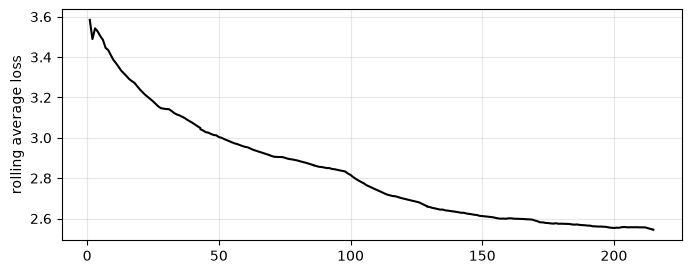

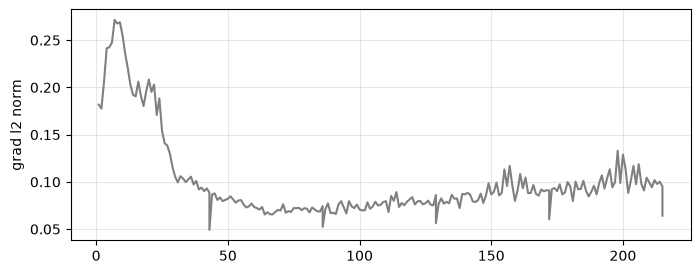

In [2]:
train_hist_df = pd.DataFrame(state['loss_hist'])
train_hist_df['step'] = train_hist_df['step'] + (43 * train_hist_df['epoch'])

# loss history
plt.figure(figsize=(8, 3))
plt.plot(train_hist_df['step'], train_hist_df['loss'], color='black')
plt.ylabel('rolling average loss')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(train_hist_df['step'], train_hist_df['grad_norm'], color='grey')
plt.ylabel('grad l2 norm')
plt.grid(alpha=0.3)
plt.show()

most interestingly, how does the LoRA post-trained net produce responses compared to the full-weight trained? we must first define an `apply_lora` function which loads in the state and applies the `LoRALinear` modules onto the original `TransformerNet` module before we load in the saved state, which has the `LoRALinear` modules saved down.

In [9]:
def apply_lora(state: State, config: Config, optimiser_map: dict) -> None:
    if not config.lora_r:
        return

    for p in state.net.parameters():
        p.requires_grad = False
    for module in list(state.net.modules()):
        for child_name, child in list(module.named_children()):
            if isinstance(child, nn.Linear) and child_name in config.lora_targets:
                setattr(module, child_name, LoRALinear(child, config.lora_r, config.lora_alpha))

    state.net.to(state.device)
    trainable = [p for p in state.net.parameters() if p.requires_grad]
    state.optimiser = optimiser_map[config.optimiser](
        trainable, lr=config.learning_rate, weight_decay=config.weight_decay
    )

we use the same prompts as we used in the full-weight post-training notebook.

In [10]:
with open(f'{CONFIG_PATH}/lora.yaml', 'r') as file:
    config = Config(**yaml.safe_load(file)['config'])

device = torch.device('cuda')
tokeniser = AutoTokenizer.from_pretrained("notoverfit/askwiki", subfolder="tokenizer")

# create state object and load in trained net
state_obj = generate_state(config, {'AdamW': torch.optim.AdamW})
apply_lora(state_obj, config, {'AdamW': torch.optim.AdamW})
state_obj.load_state_dict(state)

In [16]:
prompts = [
    'What did Marie Curie discover?',
    'Who was Isaac Newton?',
    'What is the capital of France?',
    'Which country is the Great Wall located in?',
    'What language is spoken in Brazil?',
    'Who painted the Mona Lisa?',
    'What is the largest ocean on Earth?',
    'Who was the first person to walk on the Moon?',
    'What is Japan famous for?',
    'Where is Mount Everest?',
]

MAX_NEW_TOKENS = 128
torch.manual_seed(0)

rows = []
for p in prompts:
    # i raise the temperature on the base model as it has a tendency to repeat words at lower temps.
    lora_out = chat_v2(state_obj.net, tokeniser, device, p, temperature=0.5, max_new_tokens=MAX_NEW_TOKENS)
    rows.append({'prompt': p, 'lora': lora_out})

    print(f'>>> {p}')
    print(textwrap.fill(f'[lora]  {lora_out}', width=110, subsequent_indent='       '))
    print()

>>> What did Marie Curie discover?
[lora]  Marie Curie discovered the possibility of the concept of the "inferior" and "creative" in a book of
       the same name by her colleague and colleague, Paul Carpentier.

>>> Who was Isaac Newton?
[lora]  Isaac Newton (1738–1807) was a British politician who served as the Member of Parliament (MP) for the
       constituency of East Sussex.

>>> What is the capital of France?
[lora]  The capital of France is the capital of the department of Rennes.

>>> Which country is the Great Wall located in?
[lora]  The Great Wall is located in the Meuse Valley of France. The Wall is located in the valley of the
       Meuse.

>>> What language is spoken in Brazil?
[lora]  It is spoken in the state of Pará.

>>> Who painted the Mona Lisa?
[lora]  The painting was painted by the Italian painter Luigi Parente.

>>> What is the largest ocean on Earth?
[lora]  The largest ocean on Earth is the Moon.

>>> Who was the first person to walk on the Moon?
[lora]  T

so the model is still overconfident and gets most facts wrong, but the brilliant fact is that the Q&A format has been embedded into the model through an extremely low rank matrix of $r=8$. i mean, just think about how many little parameters we've updated compare to the original full-weight post-training. we've applied LoRA on the attention component of each block; each weight matrix has dimension $W_k, W_q, W_v, W_o \in \mathbb{R}^{d \times d}$ where $d$ is the embedding dimension. thus each layer has $d \times d$ parameters, for a total of $4d^2$ parameters per attention component.

with LoRA applied, we collapse each weight matrix to $W = W_0 + \frac{\alpha}{r}BA$ where $B \in \mathbb{R}^{d, 8}$ and $A \in \mathbb{R}^{8, d}$ for $W_0$ and $B \in \mathbb{R}^{3d \times 8}$ for $W_k, W_q, W_v$. note that $W_0$ is the original model weight and stays unchanged. thus, we have a total of $48d$ parameters to update per block, a linear improvement from $4d^2$. whilst our model is quite small, this is a massive computational saving compared to full-weight training.

> also, LoRA modules are 'attachable'; that is, you can train LoRA modules for many different domains that require post-training, and then serve the base model + LoRA modules attached down stream to any clients. this means that training costs and post-training costs (computational or otherwise) reduce significantly.